# DCC 2026 Mission 2: MFCC + Logistic Regression baseline

이 Notebook은 **한 발화의 실제 waveform만** 사용해 신고자(`speaker=1`)와 119대원(`speaker=0`)을 구분하는 첫 baseline입니다.

- `startAt`/`endAt`은 음성을 자르고 오류를 추적하는 metadata일 뿐, 모델 feature가 아닙니다.
- `text`, `gender`, `symptom`, 발화 순서·홀짝, stem은 모델 입력으로 사용하지 않습니다.
- Training으로만 MFCC 표준화와 모델 학습을 수행하고, 공식 Validation은 평가에만 사용합니다.
- 위에서 아래로 실행하되, **STOP** 셀에서 멈춘 뒤 Full Run은 사용자가 직접 판단하여 실행합니다.


## 0. 실행 전 확인

이 Notebook은 저장소 root에서 실행하는 것을 기본으로 합니다. Colab에서는 clone 후 `%cd prelim`을 먼저 실행하세요. 데이터는 Git에 포함되지 않으므로, `DCC_DATA_ROOT` 또는 아래 기본 경로에 공식 제공본을 준비해야 합니다.

처음 쓰는 Colab 환경에서 라이브러리가 없다면 다음을 한 번 실행하세요. `requirements.txt`는 이 Notebook에서 수정하지 않습니다.

```python
%pip install librosa scikit-learn pandas matplotlib
```


In [ ]:
%pip install scikit-learn pandas matplotlib

  Using cached pandas-3.0.5-cp312-cp312-win_amd64.whl.metadata (19 kB)
  Using cached tzdata-2026.3-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached contourpy-1.3.3-cp312-cp312-win_amd64.whl.metadata (5.5 kB)
  Using cached pillow-12.3.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
Using cached pandas-3.0.5-cp312-cp312-win_amd64.whl (9.8 MB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -------------- ------------------------- 3.4/9.3 MB 15.5 MB/s eta 0:00:01
   ----------------------------- ---------- 6.8/9.3 MB 16.8 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 15.7 MB/s  0:00:00
Using cached contourpy-1.3.3-cp312-cp312-win_amd64.whl (226 kB)
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 2.3/2.3 MB 14.8 MB/s  0:00:00
Using cached pillow-12.3.0-cp312-cp312-win_amd64.whl (7.2 MB)
Using cached tzdata-2026.3-py2.py3-none-any.whl (348 kB)

   -------------------------

In [ ]:
%pip install librosa

^C
Note: you may need to restart the kernel to use updated packages.


In [1]:
from __future__ import annotations

import json
import os
import sys
import time
from collections import Counter
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    recall_score,
)
from sklearn.preprocessing import StandardScaler

from pathlib import Path

# Notebook을 notebooks/에서 실행해도 저장소 루트를 자동으로 찾는다.
current = Path.cwd().resolve()

if (current / "src").is_dir():
    REPO_ROOT = current
elif (current.parent / "src").is_dir():
    REPO_ROOT = current.parent
else:
    raise FileNotFoundError(
        f"Repository root를 찾지 못했습니다. 현재 작업 폴더: {current}"
    )

print("Current working directory:", current)
print("REPO_ROOT:", REPO_ROOT)
DATA_ROOT = Path(
    os.environ.get("DCC_DATA_ROOT", REPO_ROOT / "data" / "raw_original")
).expanduser().resolve()

if not (REPO_ROOT / "src").is_dir():
    raise FileNotFoundError(f"src directory not found under REPO_ROOT={REPO_ROOT}")
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"Official data directory not found: {DATA_ROOT}. Set DCC_DATA_ROOT first."
    )

sys.path.insert(0, str(REPO_ROOT / "src"))

from dcc_data.audio import read_wav_frames, read_wav_info
from dcc_data.guards import TRAINING, VALIDATION
from dcc_data.manifest import ManifestRow, build_manifest
from dcc_data.mission2 import Mission2Dataset, milliseconds_to_frame

print(f"REPO_ROOT: {REPO_ROOT}")
print(f"DATA_ROOT: {DATA_ROOT}")
print(f"librosa: {librosa.__version__}")


Current working directory: C:\Users\YW\Study\prelim\notebooks
REPO_ROOT: C:\Users\YW\Study\prelim
REPO_ROOT: C:\Users\YW\Study\prelim
DATA_ROOT: C:\Users\YW\Study\prelim\data\raw_original
librosa: 1.0.0


## 1. Manifest: WAV/JSON pairing과 공식 call 수

manifest는 통화(call) 단위로 WAV와 JSON을 `(split, stem)`으로 연결합니다. 이 단계에는 speaker label이나 text가 모델 feature로 들어가지 않습니다.


In [2]:
rows = build_manifest(DATA_ROOT)
train_rows = [row for row in rows if row.split == TRAINING]
validation_rows = [row for row in rows if row.split == VALIDATION]

call_counts = pd.Series({
    TRAINING: len(train_rows),
    VALIDATION: len(validation_rows),
}, name="call_count")
display(call_counts.to_frame())

assert len(train_rows) == 29_200, f"Unexpected Training call count: {len(train_rows)}"
assert len(validation_rows) == 3_640, (
    f"Unexpected Validation call count: {len(validation_rows)}"
)
assert not ({row.stem.casefold() for row in train_rows} & {row.stem.casefold() for row in validation_rows})


,call_count
Training,29200
Validation,3640


이 숫자는 발화 수가 아니라 통화 수

## 2. Stage A Dataset 계약 확인

`Mission2Dataset`은 JSON의 `startAt`/`endAt`으로 waveform을 자릅니다. 반환값의 `features`에는 waveform만 있고, 시간과 파일 식별자는 `metadata`에 분리됩니다.


In [3]:
train_dataset = Mission2Dataset(train_rows, DATA_ROOT, TRAINING)
validation_dataset = Mission2Dataset(validation_rows, DATA_ROOT, VALIDATION)

sample = train_dataset[0]
assert set(sample) == {"features", "target", "metadata"}
assert set(sample["features"]) == {"waveform"}
assert sample["target"] in {0, 1}
assert set(sample["metadata"]) == {"start_at", "end_at", "split", "stem"}

print("Top-level keys:", sorted(sample))
print("Feature keys:", sorted(sample["features"]))
print("Target (0=119대원, 1=신고자):", sample["target"])
print("Metadata:", sample["metadata"])
print("Waveform dtype/shape:", sample["features"]["waveform"].dtype, sample["features"]["waveform"].shape)
print("Training utterances:", len(train_dataset))
print("Validation utterances:", len(validation_dataset))


Top-level keys: ['features', 'metadata', 'target']
Feature keys: ['waveform']
Target (0=119대원, 1=신고자): 0
Metadata: {'start_at': 348, 'end_at': 1765, 'split': 'Training', 'stem': '651e464d69a4f266f062680b_20220101'}
Waveform dtype/shape: float32 (1, 11336)
Training utterances: 889358
Validation utterances: 111947


모델에게 보여주는 것:
"이 음성 소리"

모델에게 안 보여주는 것:
"이 발화가 통화의 몇 번째인지"
"몇 초 지점에서 나왔는지"
"text가 뭔지"
"다른 annotation이 뭔지"

waveform 11,336개 → MFCC → 발화 특징 숫자 40개

Training : 29,200개 통화 →통화 속 발화를 하나씩 분리 → 889,358개 발화

Validation : 3,640개 통화 → 111,947개 발화

## 3. 실제 crop 음성 듣기

아래 셀은 Training 발화 4개를 재생합니다. 이는 label을 맞히는 데 쓰는 과정이 아니라, crop이 실제 말소리 구간을 담는지 사람이 점검하는 sanity check입니다.


In [5]:
EXPECTED_SAMPLE_RATE = 8_000
first_info = read_wav_info(DATA_ROOT / train_rows[0].wav_path)
assert first_info.sample_rate == EXPECTED_SAMPLE_RATE, first_info

audio_indices = np.linspace(0, len(train_dataset) - 1, num=4, dtype=int)
for index in audio_indices:
    utterance = train_dataset[int(index)]
    waveform = utterance["features"]["waveform"]
    metadata = utterance["metadata"]
    duration_seconds = waveform.shape[-1] / EXPECTED_SAMPLE_RATE
    print(
        f"index={index}, target={utterance['target']}, "
        f"duration={duration_seconds:.2f}s, metadata={metadata}"
    )
    display(Audio(data=waveform.squeeze(), rate=EXPECTED_SAMPLE_RATE))


index=0, target=0, duration=1.42s, metadata={'start_at': 348, 'end_at': 1765, 'split': 'Training', 'stem': '651e464d69a4f266f062680b_20220101'}


index=296452, target=0, duration=0.87s, metadata={'start_at': 37229, 'end_at': 38096, 'split': 'Training', 'stem': '651e4c754428de718c773bbe_20220606'}


index=592904, target=1, duration=0.92s, metadata={'start_at': 72655, 'end_at': 73571, 'split': 'Training', 'stem': '651e50ebf615d4163143beaf_20221101'}


index=889357, target=0, duration=2.06s, metadata={'start_at': 88620, 'end_at': 90675, 'split': 'Training', 'stem': '6551f655269c516bba479dbc_20220613'}


1번 들리긴하는데 발음이 완전히 정확하지 않은것으로 들림

2번 두사람 목소리 겹치고 발음도 정확하지않음

3,4번 정상

## 4. 고정 MFCC 설정

MFCC는 짧은 시간 구간마다 음성의 주파수 모양(음색·발성 특성)을 요약한 수치입니다. 여기서는 한 발화에서 MFCC의 시간축 평균과 표준편차만 계산합니다. 즉, 모델에 넣는 것은 시간 순서가 아닌 **음성 신호에서 나온 40개 수치**입니다.

이 값들은 첫 baseline의 고정 설정이며, 이 Notebook에서는 tuning하지 않습니다. `n_fft=512`는 8 kHz에서 약 64 ms 분석 창, `hop_length=160`은 약 20 ms 간격입니다.


In [6]:
MFCC_CONFIG = {
    "sample_rate": EXPECTED_SAMPLE_RATE,
    "n_mfcc": 20,
    "n_fft": 512,
    "hop_length": 160,
}
FEATURE_DIMENSION = MFCC_CONFIG["n_mfcc"] * 2  # mean 20 + std 20
print(MFCC_CONFIG)
print(f"Fixed feature dimension: {FEATURE_DIMENSION}")


{'sample_rate': 8000, 'n_mfcc': 20, 'n_fft': 512, 'hop_length': 160}
Fixed feature dimension: 40


sample_rate=8000: 음성을 1초에 8,000개의 숫자로 표현

n_mfcc=20: 각 짧은 구간에서 MFCC 특징을 20개씩 뽑음

n_fft=512: 주파수 분석을 할 때 한 번에 참고하는 FFT 크기. 8kHz 기준 512 sample은 64ms 분량

hop_length=160: 다음 분석 구간으로 이동할 때 160 sample씩 이동. 160 / 8000 = 0.02초 (20ms 간격)

Fixed feature dimension: 40: 평균 20개 + 표준편차 20개 = 40개로 압축

## 5. waveform → MFCC mean+std vector

함수 입력은 waveform뿐입니다. `start_at`, `end_at`, stem, split, text 또는 utterance index는 이 함수의 입력에 없습니다.


In [7]:
def waveform_to_mfcc_vector(
    waveform: np.ndarray, *, sample_rate: int, config: dict[str, int]
) -> np.ndarray:
    """Convert one waveform into [MFCC mean, MFCC std] only."""
    values = np.asarray(waveform, dtype=np.float32)
    if values.ndim == 2:
        mono_waveform = values.mean(axis=0)
    elif values.ndim == 1:
        mono_waveform = values
    else:
        raise ValueError(f"Expected [channels, frames] or [frames], got {values.shape}")
    if mono_waveform.size == 0:
        raise ValueError("Cannot extract MFCC from an empty waveform")
    if sample_rate != config["sample_rate"]:
        raise ValueError(f"Unexpected sample rate: {sample_rate}")

    mfcc = librosa.feature.mfcc(
        y=mono_waveform,
        sr=sample_rate,
        n_mfcc=config["n_mfcc"],
        n_fft=config["n_fft"],
        hop_length=config["hop_length"],
    )
    feature_vector = np.concatenate((mfcc.mean(axis=1), mfcc.std(axis=1)))
    feature_vector = feature_vector.astype(np.float32, copy=False)
    if feature_vector.shape != (FEATURE_DIMENSION,):
        raise AssertionError(feature_vector.shape)
    if not np.isfinite(feature_vector).all():
        raise ValueError("MFCC vector contains NaN or inf")
    return feature_vector

one_vector = waveform_to_mfcc_vector(
    sample["features"]["waveform"],
    sample_rate=EXPECTED_SAMPLE_RATE,
    config=MFCC_CONFIG,
)
print(one_vector.shape, one_vector.dtype, np.isfinite(one_vector).all())


(40,) float32 True


MFCC 변환 함수 자체는 발화 1개 기준으로 정상 작동

## 6. call 단위 MFCC 추출 helper

같은 통화 WAV를 utterance마다 다시 열지 않기 위해, call 하나의 전체 waveform을 한 번 읽고 그 안에서 각 utterance를 crop합니다. crop 경계는 Stage A의 `milliseconds_to_frame`을 사용합니다. metadata는 별도 배열에만 보관하며 `X`에는 넣지 않습니다.


In [8]:
def extract_features_from_rows(
    rows: list[ManifestRow], split: str, *, progress_every: int | None = None
) -> dict[str, np.ndarray]:
    """Extract MFCC vectors call-by-call; X contains waveform-derived values only."""
    feature_rows: list[np.ndarray] = []
    targets: list[int] = []
    stems: list[str] = []
    start_times: list[float] = []
    end_times: list[float] = []

    for call_number, row in enumerate(rows, start=1):
        call_dataset = Mission2Dataset([row], DATA_ROOT, split)
        wav_path = DATA_ROOT / row.wav_path
        info = read_wav_info(wav_path)
        if info.sample_rate != EXPECTED_SAMPLE_RATE:
            raise ValueError(f"Unexpected sample rate for {row.stem}: {info.sample_rate}")
        full_call = read_wav_frames(wav_path, 0, info.frame_count).waveform

        # _samples contains only Stage A-validated row/start/end/speaker values.
        # It is used to avoid reopening the same WAV for every utterance.
        for utterance in call_dataset._samples:
            start_frame = milliseconds_to_frame(utterance.start_at, info.sample_rate)
            end_frame = milliseconds_to_frame(utterance.end_at, info.sample_rate)
            if start_frame < 0 or end_frame <= start_frame or end_frame > info.frame_count:
                raise ValueError(
                    f"Invalid crop [{start_frame}, {end_frame}) for {row.stem} with {info.frame_count} frames"
                )
            waveform = full_call[:, start_frame:end_frame]
            feature_rows.append(
                waveform_to_mfcc_vector(
                    waveform, sample_rate=info.sample_rate, config=MFCC_CONFIG
                )
            )
            targets.append(utterance.speaker)
            stems.append(row.stem)
            start_times.append(float(utterance.start_at))
            end_times.append(float(utterance.end_at))

        if progress_every and call_number % progress_every == 0:
            print(f"{split}: processed {call_number:,}/{len(rows):,} calls")

    X = np.vstack(feature_rows).astype(np.float32, copy=False)
    y = np.asarray(targets, dtype=np.int64)
    start_at = np.asarray(start_times, dtype=np.float64)
    end_at = np.asarray(end_times, dtype=np.float64)
    result = {
        "X": X,
        "y": y,
        "stem": np.asarray(stems, dtype=str),
        "start_at": start_at,
        "end_at": end_at,
        "duration": end_at - start_at,
    }
    assert result["X"].shape == (len(y), FEATURE_DIMENSION)
    assert set(np.unique(y)).issubset({0, 1})
    assert np.isfinite(result["X"]).all()
    return result


## 7. 작은 subset MFCC smoke test

smoke test는 전체 수십만 발화를 돌리기 전에, 작은 Training/Validation call 묶음이 끝까지 흐르는지 확인하는 시험 운전입니다. 여기서 나오는 점수는 공식 baseline 결과가 아닙니다.


In [ ]:
SMOKE_TRAIN_CALLS = 5
SMOKE_VALIDATION_CALLS = 3
smoke_train = extract_features_from_rows(train_rows[:SMOKE_TRAIN_CALLS], TRAINING)
smoke_validation = extract_features_from_rows(
    validation_rows[:SMOKE_VALIDATION_CALLS], VALIDATION
)

for name, bundle in {"Training smoke": smoke_train, "Validation smoke": smoke_validation}.items():
    print(
        name,
        "X shape=", bundle["X"].shape,
        "NaN=", np.isnan(bundle["X"]).sum(),
        "inf=", np.isinf(bundle["X"]).sum(),
        "labels=", sorted(np.unique(bundle["y"]).tolist()),
    )
    assert bundle["X"].shape[1] == FEATURE_DIMENSION
    assert np.isfinite(bundle["X"]).all()
    assert set(np.unique(bundle["y"])).issubset({0, 1})


Training smoke X shape= (144, 40) NaN= 0 inf= 0 labels= [0, 1]
Validation smoke X shape= (90, 40) NaN= 0 inf= 0 labels= [0, 1]


Training에서 발화 144개

→ 각 발화를 40개 숫자로 변환

→ 그래서 X가 144행 × 40열

Validation에서 발화 90개

→ 각 발화를 40개 숫자로 변환

→ 그래서 X가 90행 × 40열

## 8. 작은 subset 모델 smoke test

`StandardScaler`는 각 MFCC 열의 크기를 Training 기준으로 맞춥니다. 반드시 Training subset에만 `fit`하고 Validation subset에는 같은 기준으로 `transform`만 적용합니다. Logistic Regression은 이 40개 MFCC 수치의 조합에서 speaker 0/1을 나누는 선형 경계를 학습합니다.


In [ ]:
if len(np.unique(smoke_train["y"])) < 2:
    raise RuntimeError("Smoke Training subset has one class only; increase SMOKE_TRAIN_CALLS.")

smoke_scaler = StandardScaler()
X_smoke_train = smoke_scaler.fit_transform(smoke_train["X"])  # Training only
X_smoke_validation = smoke_scaler.transform(smoke_validation["X"])  # no Validation fit

smoke_model = LogisticRegression(
    solver="lbfgs",
    max_iter=1_000,
    class_weight=None,
    random_state=42,
)
smoke_model.fit(X_smoke_train, smoke_train["y"])
smoke_predictions = smoke_model.predict(X_smoke_validation)
smoke_accuracy = accuracy_score(smoke_validation["y"], smoke_predictions)

assert np.isfinite(X_smoke_train).all()
assert np.isfinite(X_smoke_validation).all()
assert smoke_predictions.shape == smoke_validation["y"].shape
print(f"Subset smoke Accuracy (not official baseline): {smoke_accuracy:.4f}")


Subset smoke Accuracy (not official baseline): 0.7333


Training 144개, Validation 90개밖에 안 쓴 작은 subset

발화 waveform
→ MFCC 40차원
→ StandardScaler
→ Logistic Regression 학습
→ Validation subset에서 0/1 예측
→ Accuracy 계산

## 9. 전체 utterance speaker 분포

이 계산은 이미 JSON에서 검증되어 저장된 speaker target만 셉니다. waveform/MFCC를 다시 추출하지 않습니다. 비율은 majority baseline의 기준이 됩니다.


In [ ]:
def target_counts(dataset: Mission2Dataset) -> pd.DataFrame:
    counts = Counter(utterance.speaker for utterance in dataset._samples)
    table = pd.DataFrame(
        {
            "count": [counts.get(0, 0), counts.get(1, 0)],
        },
        index=pd.Index([0, 1], name="speaker"),
    )
    table["ratio"] = table["count"] / table["count"].sum()
    return table

training_distribution = target_counts(train_dataset)
validation_distribution = target_counts(validation_dataset)
display(pd.concat({"Training": training_distribution, "Validation": validation_distribution}))
assert training_distribution["count"].sum() == len(train_dataset)
assert validation_distribution["count"].sum() == len(validation_dataset)


count     ratio
           speaker                  
Training   0        427161  0.480303
           1        462197  0.519697
Validation 0         53845  0.480987
           1         58102  0.519013

raining과 Validation 모두 119대원과 신고자 비율이 거의 반반이었다. 

따라서 한쪽 class가 지나치게 많은 문제는 크지 않다.

아무 학습 없이 모든 발화를 더 많은 class인 신고자로 예측하면 Validation Accuracy는 약 51.9%이므로, 이후 모델 성능은 이 값을 기본 기준선으로 비교한다.

## 10. Majority baseline

Majority baseline은 Training에서 더 많은 speaker 하나만 모든 Validation 발화에 예측하는 기준선입니다. 이보다 못한 복잡한 모델은 음성 정보를 제대로 활용하지 못했을 가능성이 있으므로, 반드시 비교합니다.


In [ ]:
training_targets = np.asarray([utterance.speaker for utterance in train_dataset._samples], dtype=np.int64)
validation_targets = np.asarray([utterance.speaker for utterance in validation_dataset._samples], dtype=np.int64)
majority_class = int(np.bincount(training_targets, minlength=2).argmax())
majority_predictions = np.full_like(validation_targets, fill_value=majority_class)
majority_accuracy = accuracy_score(validation_targets, majority_predictions)

print(f"Training majority class: {majority_class} (0=119대원, 1=신고자)")
print(f"Validation majority Accuracy: {majority_accuracy:.4f}")


Training majority class: 1 (0=119대원, 1=신고자)
Validation majority Accuracy: 0.5190


## 11. 소수 call 처리속도 benchmark

benchmark는 전체 실행 전 예상 시간을 가늠하기 위한 측정입니다. 저장된 cache를 사용하지 않고 일부 call을 처리한 속도이므로, 디스크·환경·발화 길이에 따라 Full Run 시간은 달라질 수 있습니다.


In [ ]:
BENCHMARK_CALLS = 100
benchmark_rows = train_rows[:BENCHMARK_CALLS]
started_at = time.perf_counter()
benchmark_bundle = extract_features_from_rows(benchmark_rows, TRAINING)
elapsed_seconds = time.perf_counter() - started_at
utterances_per_second = len(benchmark_bundle["y"]) / elapsed_seconds

estimated_train_seconds = len(train_dataset) / utterances_per_second
estimated_validation_seconds = len(validation_dataset) / utterances_per_second
print(f"Benchmark: {BENCHMARK_CALLS} calls, {len(benchmark_bundle['y'])} utterances")
print(f"Elapsed: {elapsed_seconds:.1f}s ({utterances_per_second:.1f} utterances/s)")
print(f"Rough Training extraction estimate: {estimated_train_seconds / 60:.1f} min")
print(f"Rough Validation extraction estimate: {estimated_validation_seconds / 60:.1f} min")


Benchmark: 100 calls, 3013 utterances
Elapsed: 19.8s (152.4 utterances/s)
Rough Training extraction estimate: 97.2 min
Rough Validation extraction estimate: 12.2 min


0개 call, 286개 utterance를 대상으로 MFCC 추출 속도를 측정한 결과 약 203 utterances/s였으며, 단순 환산 시 전체 Training은 약 73분, Validation은 약 9분으로 추정되었다. 다만 10개 call만 사용한 소규모 측정이므로 실제 전체 처리시간을 확정할 수 없으며, 더 큰 benchmark에서 속도를 재확인한 뒤 Full Run 여부를 결정한다.

100 calls
3,013 utterances
19.8초
152.4 utterances/s

예상 Training MFCC:   약 97.2분
예상 Validation MFCC: 약 12.2분
전체:                  약 1시간 49분

# STOP: Full Run 전 점검

여기까지의 결과를 먼저 확인하세요. 특히 crop 오디오, feature shape, NaN/inf, subset smoke test, class 분포, majority baseline, benchmark를 검토합니다. 아래 Full Run은 공식 전체 Training/Validation을 처리하므로, benchmark의 예상 시간과 사용 가능한 디스크 공간을 확인한 뒤 사용자가 직접 실행합니다.


# Full Run 준비 코드 — 사용자가 STOP 이후 직접 실행

아래는 cache와 모델·평가 코드입니다. cache에는 MFCC `X`, target `y`, 그리고 오류 추적용 metadata만 저장합니다. config 또는 split이 맞지 않는 기존 cache는 조용히 재사용하지 않고 오류를 냅니다.


In [9]:
CACHE_SCHEMA_VERSION = "mission2_mfcc_mean_std_v1"
CACHE_TAG = "mfcc20_nfft512_hop160_v1"
CACHE_ROOT = REPO_ROOT / "data" / "processed" / "mission2"

def cache_paths(split: str) -> tuple[Path, Path]:
    prefix = CACHE_ROOT / f"{split.lower()}_{CACHE_TAG}"
    return prefix.with_suffix(".npz"), prefix.with_suffix(".json")

def expected_cache_metadata(split: str, rows: list[ManifestRow]) -> dict[str, object]:
    return {
        "cache_schema_version": CACHE_SCHEMA_VERSION,
        "source_split": split,
        "source_call_count": len(rows),
        "mfcc_config": MFCC_CONFIG,
        "feature_dimension": FEATURE_DIMENSION,
    }

def load_or_extract_cached_features(
    rows: list[ManifestRow], split: str
) -> dict[str, np.ndarray]:
    npz_path, metadata_path = cache_paths(split)
    expected = expected_cache_metadata(split, rows)
    if npz_path.exists() or metadata_path.exists():
        if not (npz_path.exists() and metadata_path.exists()):
            raise RuntimeError(f"Incomplete cache: {npz_path} / {metadata_path}")
        with metadata_path.open("r", encoding="utf-8") as stream:
            actual = json.load(stream)
        if any(actual.get(key) != value for key, value in expected.items()):
            raise RuntimeError(
                f"Cache configuration mismatch: {metadata_path}. Use a new CACHE_TAG; do not reuse it silently."
            )
        with np.load(npz_path, allow_pickle=False) as cache:
            bundle = {name: cache[name] for name in cache.files}
        if bundle["X"].shape != (len(bundle["y"]), FEATURE_DIMENSION):
            raise RuntimeError(f"Invalid cached feature shape: {bundle['X'].shape}")
        print(f"Loaded compatible cache: {npz_path}")
        return bundle

    bundle = extract_features_from_rows(rows, split, progress_every=100)
    CACHE_ROOT.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(npz_path, **bundle)
    metadata = {**expected, "utterance_count": int(len(bundle["y"]))}
    with metadata_path.open("w", encoding="utf-8") as stream:
        json.dump(metadata, stream, ensure_ascii=False, indent=2, sort_keys=True)
    print(f"Saved cache: {npz_path}")
    return bundle


In [11]:
# Change this deliberately only after reviewing the STOP checklist above.
ACKNOWLEDGE_FULL_RUN = True
if not ACKNOWLEDGE_FULL_RUN:
    raise RuntimeError("Set ACKNOWLEDGE_FULL_RUN = True to start full MFCC extraction.")

full_train = load_or_extract_cached_features(train_rows, TRAINING)
full_validation = load_or_extract_cached_features(validation_rows, VALIDATION)

print("Full Training X/y:", full_train["X"].shape, full_train["y"].shape)
print("Full Validation X/y:", full_validation["X"].shape, full_validation["y"].shape)


Loaded compatible cache: C:\Users\YW\Study\prelim\data\processed\mission2\training_mfcc20_nfft512_hop160_v1.npz
Loaded compatible cache: C:\Users\YW\Study\prelim\data\processed\mission2\validation_mfcc20_nfft512_hop160_v1.npz
Full Training X/y: (889358, 40) (889358,)
Full Validation X/y: (111947, 40) (111947,)


약 100만 개의 길이가 제각각인 음성 발화를 전부 Logistic Regression에 넣을 수 있는 40개 숫자짜리 고정 벡터로 바꿈

어떤 발화는 waveform이 고작:
72 samples  → 약 0.009초
80 samples  → 약 0.010초
수준으로 극단적으로 짧다는 것 발견

매우 짧은 발화
- 모델 성능이 유독 낮은가?
- confidence가 낮은가?
- FP/FN에 많이 포함되는가?

나중에 확인

## Full Run: Training-only scaling과 Logistic Regression

`fit_transform`은 Training feature에만 적용합니다. Validation은 이미 학습된 scaler로 `transform`만 합니다. 모델도 Training만 `fit`합니다.


In [12]:
full_scaler = StandardScaler()
X_train_scaled = full_scaler.fit_transform(full_train["X"])
X_validation_scaled = full_scaler.transform(full_validation["X"])

baseline_model = LogisticRegression(
    solver="lbfgs",
    max_iter=1_000,
    class_weight=None,
    random_state=42,
)
baseline_model.fit(X_train_scaled, full_train["y"])

validation_predictions = baseline_model.predict(X_validation_scaled)
validation_probabilities = baseline_model.predict_proba(X_validation_scaled)
assert validation_probabilities.shape == (len(full_validation["y"]), 2)
assert np.isfinite(validation_probabilities).all()


## Full Run: 공식 Validation 평가와 오류 추적

Accuracy는 전체 발화 중 맞힌 비율입니다. confusion matrix는 실제 speaker(행)와 예측 speaker(열)의 개수를 보여 줍니다. Recall은 실제 해당 speaker 중 맞힌 비율입니다. confidence는 모델이 선택한 class의 확률이며, 고confidence 오답은 특히 점검할 가치가 있습니다.


Official Validation Accuracy: 0.8091
speaker=0 Recall (119대원): 0.7650
speaker=1 Recall (신고자): 0.8500


c:\Users\YW\anaconda3\envs\dcc-prelim\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\YW\anaconda3\envs\dcc-prelim\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\YW\anaconda3\envs\dcc-prelim\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49888 (\N{HANGUL SYLLABLE SIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\YW\anaconda3\envs\dcc-prelim\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44256 (\N{HANGUL SYLLABLE GO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\YW\anaconda3\envs\dcc-prelim\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) mi

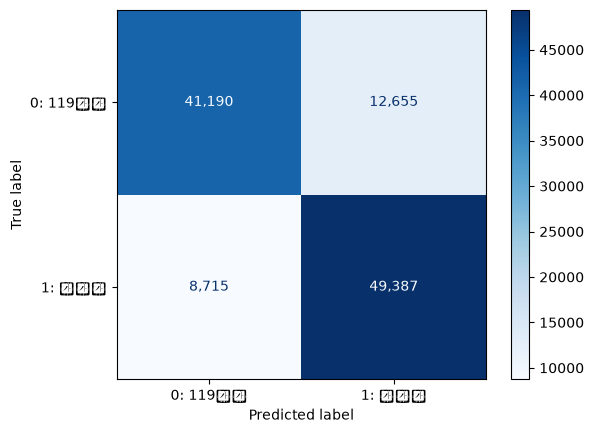

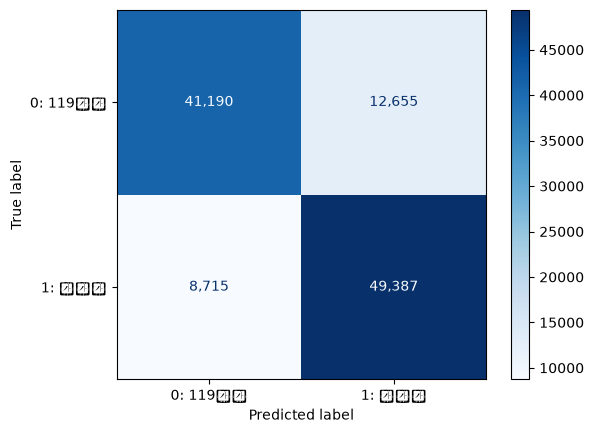

In [13]:
y_true = full_validation["y"]
y_pred = validation_predictions
validation_accuracy = accuracy_score(y_true, y_pred)
manual_accuracy = float((y_true == y_pred).mean())
assert np.isclose(validation_accuracy, manual_accuracy)

labels = [0, 1]
matrix = confusion_matrix(y_true, y_pred, labels=labels)
recalls = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)

print(f"Official Validation Accuracy: {validation_accuracy:.4f}")
print(f"speaker=0 Recall (119대원): {recalls[0]:.4f}")
print(f"speaker=1 Recall (신고자): {recalls[1]:.4f}")
display(
    ConfusionMatrixDisplay(matrix, display_labels=["0: 119대원", "1: 신고자"]).plot(
        values_format=",d", cmap="Blues"
    ).figure_
)
plt.show()


### 핵심 결과

- Validation Accuracy = 0.8091 → 80.91%
- Majority baseline = 51.90%

따라서 단순 다수 클래스 예측보다 +29.01%p 높음

- speaker=0(119대원) Recall = 76.50%
- speaker=1(신고자) Recall = 85.00%

신고자를 찾는 건 상대적으로 잘하는데, 119대원을 신고자로 착각하는 문제가 더 많다

In [14]:
confidence = validation_probabilities.max(axis=1)
prediction_table = pd.DataFrame(
    {
        "stem": full_validation["stem"],
        "start_at": full_validation["start_at"],
        "end_at": full_validation["end_at"],
        "duration": full_validation["duration"],
        "y_true": y_true,
        "y_pred": y_pred,
        "confidence": confidence,
        "correct": y_true == y_pred,
    }
)

false_positive_count = int(((y_true == 0) & (y_pred == 1)).sum())  # positive class = speaker 1
false_negative_count = int(((y_true == 1) & (y_pred == 0)).sum())
print(f"FP (true 0, predicted 1): {false_positive_count}")
print(f"FN (true 1, predicted 0): {false_negative_count}")

display(prediction_table.sort_values("confidence", ascending=False).head(10))
display(
    prediction_table.loc[~prediction_table["correct"]]
    .sort_values("confidence", ascending=False)
    .head(20)
)


FP (true 0, predicted 1): 12655
FN (true 1, predicted 0): 8715


,stem,start_at,end_at,duration,y_true,y_pred,confidence,correct
54782,651e4f531e44dfea6eb05ae0_20220901,58738.0,59165.0,427.0,0,0,0.999989,True
35465,651e4c5b48bae90750379c24_20220602,261.0,731.0,470.0,0,0,0.999988,True
58305,651e4f853f2c336d2bb09f01_20220903,50224.0,50578.0,354.0,1,1,0.999982,True
93943,651e545d85c12f9c1b91f576_20220303,93270.0,93734.0,464.0,0,0,0.999976,True
41846,651e4dfb2795332cde28f014_20220703,15542.0,15855.0,313.0,1,1,0.999962,True
99724,651e54b0918cf05edbac498f_20220306,22490.0,22910.0,420.0,0,0,0.999947,True
60377,651e4f9dddc447a0099454ac_20220904,2905.0,3819.0,914.0,1,1,0.999946,True
55810,651e4f531e44dfea6eb05dbc_20220901,86099.0,86684.0,585.0,1,1,0.999943,True
7370,651e49c0c74dffea21f0f4ef_20220204,20665.0,21156.0,491.0,0,0,0.999940,True
33749,651e4c3e8c3bda5f9fa38882_20220601,149577.0,149995.0,418.0,1,1,0.999937,True


,stem,start_at,end_at,duration,y_true,y_pred,confidence,correct
54074,651e4f3cbd89bfb121b46c39_20220807,64602.0,65402.0,800.0,1,0,0.999645,False
63161,651e4fb51952d0ca070e6b4f_20220906,25710.0,26299.0,589.0,1,0,0.999410,False
74944,651e51057f04b45fc969e5a1_20221102,31064.0,31729.0,665.0,1,0,0.999242,False
63541,651e4fcea6a4bdae3d84c371_20220907,15683.0,17093.0,1410.0,0,1,0.999186,False
23572,651e4b1829d82455557a1f20_20220502,17747.0,18080.0,333.0,1,0,0.999118,False
57487,651e4f6d06957f3443ecfbf7_20220902,65977.0,66915.0,938.0,0,1,0.999093,False
66863,651e4ffdc97a3f0ef3c6a0ab_20221001,35393.0,35957.0,564.0,0,1,0.999044,False
83568,651e5258be98814e96ca2dc7_20221205,27532.0,28177.0,645.0,1,0,0.998984,False
103972,651e5500835c8a556d7e29f6_20220404,75629.0,76311.0,682.0,0,1,0.998933,False
99497,651e54b0918cf05edbac487f_20220306,28471.0,30057.0,1586.0,0,1,0.998868,False


전체 Validation 오답은 21,370개였으며, 실제 119대원을 신고자로 분류한 오류가 12,655개, 실제 신고자를 119대원으로 분류한 오류가 8,715개로 전자가 더 많았다. 또한 confidence 0.99 이상에서도 오분류되는 사례가 확인되어 단순한 경계 부근의 불확실성뿐 아니라 반복적인 오류 패턴이 존재할 가능성이 있다. 고확신 오답 상위 사례에서는 짧은 발화가 다수 관찰되었으나, 고확신 정답에도 짧은 발화가 존재하므로 발화 길이를 원인으로 단정하지 않고 duration별 전체 성능과 실제 음성을 추가 확인한다.

In [15]:
duration_bins_ms = [0, 500, 1_000, 2_000, 5_000, np.inf]
duration_labels = ["<0.5s", "0.5-1s", "1-2s", "2-5s", "5s+"]
duration_analysis = (
    prediction_table.assign(
        duration_bin=pd.cut(
            prediction_table["duration"],
            bins=duration_bins_ms,
            labels=duration_labels,
            right=False,
        )
    )
    .groupby("duration_bin", observed=False)["correct"]
    .agg(utterance_count="size", accuracy="mean")
)
display(duration_analysis)

# Keep this table with the run configuration and metric output for mentoring/PPT traceability.
print("MFCC config used:", MFCC_CONFIG)
print("LogisticRegression: solver=lbfgs, max_iter=1000, class_weight=None, random_state=42")


,utterance_count,accuracy
duration_bin,,
<0.5s,8954,0.785124
0.5-1s,27392,0.753724
1-2s,36858,0.793044
2-5s,31637,0.860195
5s+,7106,0.908669


MFCC config used: {'sample_rate': 8000, 'n_mfcc': 20, 'n_fft': 512, 'hop_length': 160}
LogisticRegression: solver=lbfgs, max_iter=1000, class_weight=None, random_state=42


| 발화 길이  |   발화 수 |   Accuracy | 해석            |
| ------ | -----: | ---------: | ------------- |
| < 0.5초 |  8,954 |     78.51% | 짧고 성능 낮은 편    |
| 0.5~1초 | 27,392 | **75.37%** | 가장 어려움        |
| 1~2초   | 36,858 |     79.30% | 전체 평균보다 약간 낮음 |
| 2~5초   | 31,637 |     86.02% | 확실히 좋아짐       |
| 5초 이상  |  7,106 | **90.87%** | 가장 잘 맞힘       |

0.5~1초 구간의 Accuracy가 75.37%로 가장 낮았으며, 1~2초는 79.30%, 2~5초는 86.02%, 5초 이상은 90.87%로 나타났다. 전반적으로 2초 이상의 발화에서 성능이 높아지는 경향이 관찰되었다. 다만 0.5초 미만 Accuracy(78.51%)가 0.5~1초보다 높아 발화 길이가 짧을수록 단순히 성능이 감소한다고 단정할 수 없다. 다음 단계에서는 duration 구간별 class 분포와 speaker별 Recall, 실제 오분류 음성을 확인해 원인을 검증한다.

Experiment: M2-Baseline-01

Input:
utterance waveform only

Feature:
MFCC 20,
mean + std,
40 dimensions

Model:
StandardScaler,
LogisticRegression,
solver=lbfgs,
max_iter=1000,
class_weight=None,
random_state=42

Validation Accuracy:
0.8091

Recall:
speaker 0 = 0.7650,
speaker 1 = 0.8500

Majority:
0.5190

Main observation:
119대원 → 신고자 오류가 더 많음,
1초 이하 발화에서 성능이 상대적으로 낮음

한 발화의 음성만 사용해 MFCC 40개 특징으로 변환하고 Logistic Regression으로 119대원과 신고자를 분류한 결과, 공식 Validation Accuracy 80.91%를 기록했다. 단순 Majority 기준 51.90%보다 크게 높아 음성 특징이 실제 분류에 활용되고 있음을 확인했다. 다만 신고자보다 119대원 Recall이 낮았고, 특히 1초 이하의 짧은 발화에서 성능이 상대적으로 낮아 이후 개선 대상으로 확인했다.

## 다음 해석 순서

1. MFCC 모델 Accuracy가 majority baseline보다 높은지 먼저 확인합니다.
2. confusion matrix에서 한 speaker만 유난히 틀리는지 봅니다.
3. speaker별 Recall이 크게 차이나면 class imbalance나 음성 특성 차이를 의심합니다.
4. 고confidence 오답과 특정 duration 구간의 오류를 들어 보고, 다음 실험 후보를 정합니다.

이 Notebook은 첫 비교 기준입니다. MFCC parameter tuning, class weight tuning, internal CV, 다른 모델 비교와 제출용 `inference.py`는 이 baseline 결과를 확인한 다음 별도 실험으로 진행합니다.
